# Task 5: EDA and Machine Learning - CO2 Dataset

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 1. EDA

In [2]:
df = pd.read_csv('co2.csv')
df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [3]:
df.shape

(7385, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              7385 non-null   str    
 1   Model                             7385 non-null   str    
 2   Vehicle Class                     7385 non-null   str    
 3   Engine Size(L)                    7385 non-null   float64
 4   Cylinders                         7385 non-null   int64  
 5   Transmission                      7385 non-null   str    
 6   Fuel Type                         7385 non-null   str    
 7   Fuel Consumption City (L/100 km)  7385 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   7385 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  7385 non-null   float64
 10  Fuel Consumption Comb (mpg)       7385 non-null   int64  
 11  CO2 Emissions(g/km)               7385 non-null   int64  
dtypes: float64(4), in

In [5]:
df.describe()

,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
count,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000
mean,3.160068,5.615030,12.556534,9.041706,10.975071,27.481652,250.584699
std,1.354170,1.828307,3.500274,2.224456,2.892506,7.231879,58.512679
min,0.900000,3.000000,4.200000,4.000000,4.100000,11.000000,96.000000
25%,2.000000,4.000000,10.100000,7.500000,8.900000,22.000000,208.000000
50%,3.000000,6.000000,12.100000,8.700000,10.600000,27.000000,246.000000
75%,3.700000,6.000000,14.600000,10.200000,12.600000,32.000000,288.000000
max,8.400000,16.000000,30.600000,20.600000,26.100000,69.000000,522.000000


In [6]:
# checking null values and duplicates
print(df.isnull().sum())
print(df.duplicated().sum())

Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64
1103


In [7]:
df = df.drop_duplicates()
df.shape

(6282, 12)

In [8]:
# renaming columns to make them easier to use
df.columns = ['make','model','vehicle_class','engine_size','cylinders','transmission','fuel_type',
              'fc_city','fc_hwy','fc_comb','mpg','co2']

In [9]:
df['vehicle_class'].value_counts()

vehicle_class
SUV - SMALL                 1006
MID-SIZE                     983
COMPACT                      903
SUV - STANDARD               613
SUBCOMPACT                   533
FULL-SIZE                    508
PICKUP TRUCK - STANDARD      475
TWO-SEATER                   381
MINICOMPACT                  274
STATION WAGON - SMALL        214
PICKUP TRUCK - SMALL         133
VAN - PASSENGER               66
SPECIAL PURPOSE VEHICLE       65
MINIVAN                       61
STATION WAGON - MID-SIZE      45
VAN - CARGO                   22
Name: count, dtype: int64

In [10]:
df['fuel_type'].value_counts()

fuel_type
X    3039
Z    2765
E     330
D     147
N       1
Name: count, dtype: int64

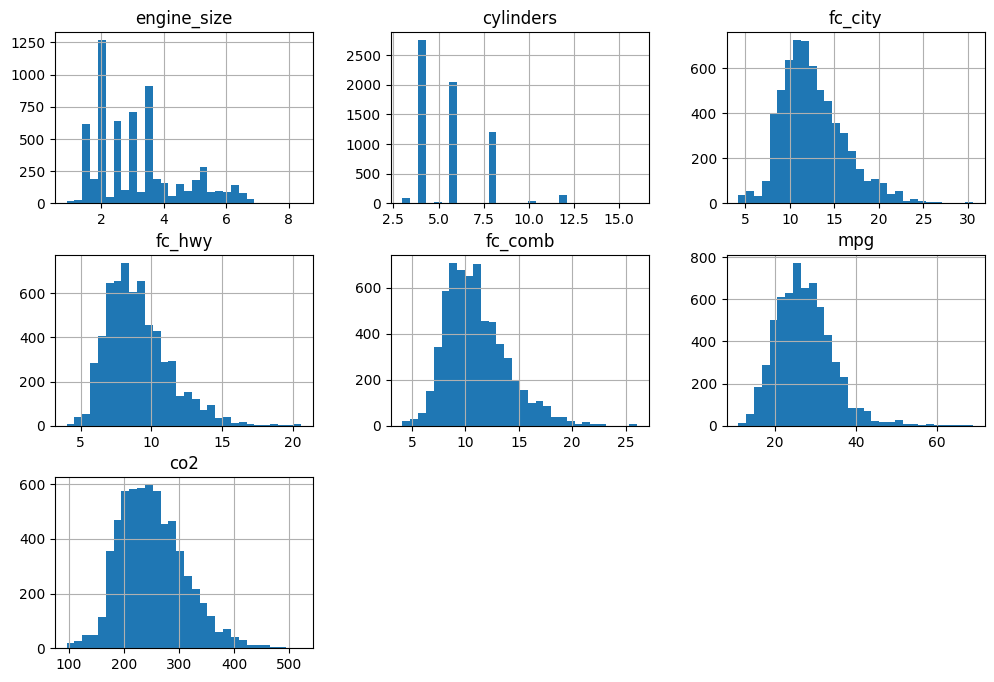

In [11]:
df.hist(figsize=(12,8), bins=30)
plt.show()

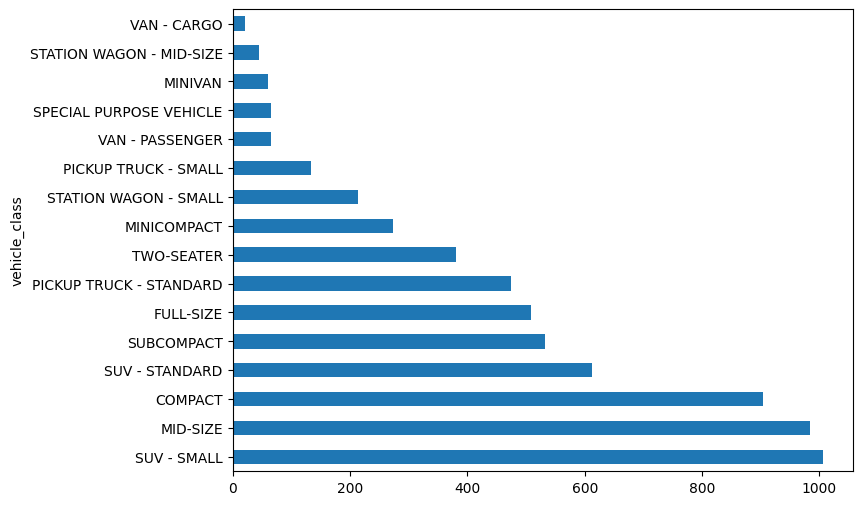

In [13]:
df['vehicle_class'].value_counts().plot(kind='barh', figsize=(8,6))
plt.show()

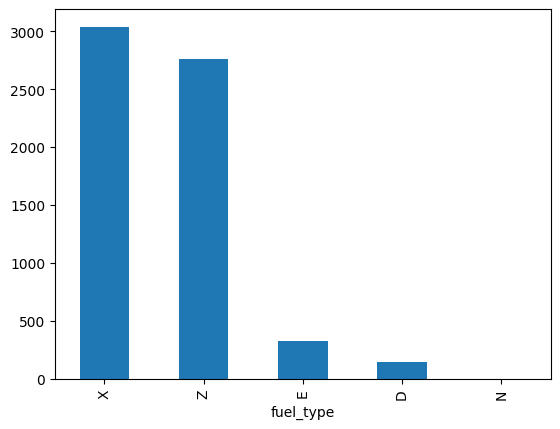

In [14]:
df['fuel_type'].value_counts().plot(kind='bar')
plt.show()

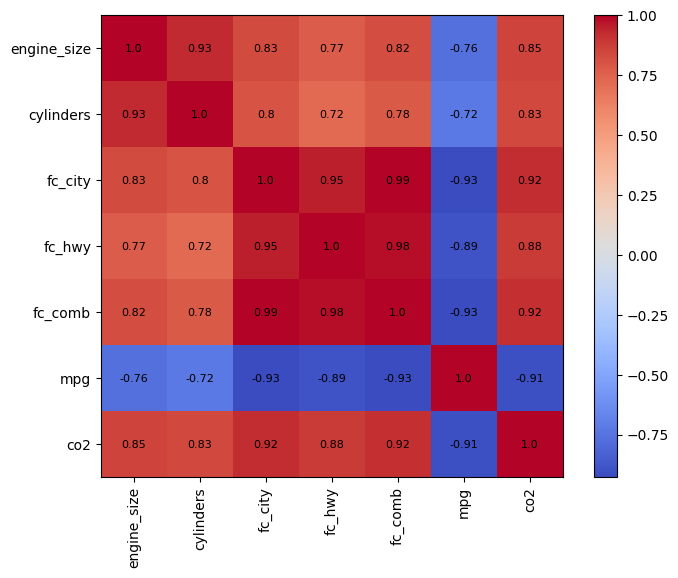

In [15]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(8,6))
plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=8)
plt.show()

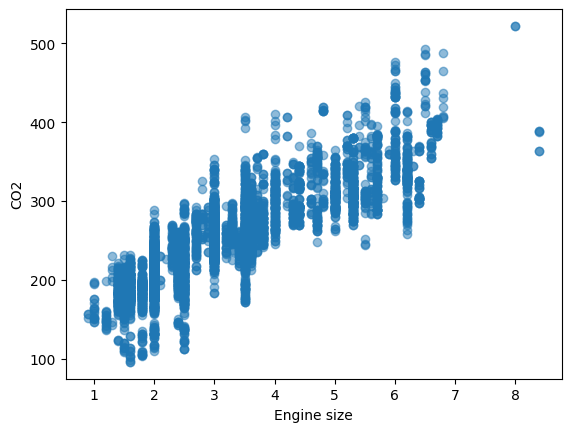

In [16]:
plt.scatter(df['engine_size'], df['co2'], alpha=0.5)
plt.xlabel('Engine size')
plt.ylabel('CO2')
plt.show()

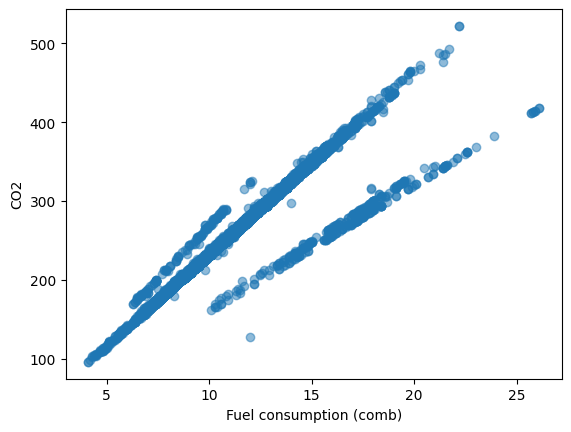

In [17]:
plt.scatter(df['fc_comb'], df['co2'], alpha=0.5)
plt.xlabel('Fuel consumption (comb)')
plt.ylabel('CO2')
plt.show()

In [20]:
# top 10 makes by average co2
df.groupby('make')['co2'].mean().sort_values(ascending=False).head(10)

make
BUGATTI         522.000000
LAMBORGHINI     402.270270
SRT             389.000000
ROLLS-ROYCE     388.750000
BENTLEY         367.914286
ASTON MARTIN    344.282051
MASERATI        318.134615
GMC             300.529412
RAM             294.180556
LAND ROVER      288.078947
Name: co2, dtype: float64

From the plots, CO2 increases with engine size, cylinders and fuel consumption. Fuel consumption has the highest correlation with CO2.

## 2. Linear Regression

### Simple linear regression (engine size vs CO2)

In [21]:
X = df[['engine_size']]
y = df['co2']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)
print(lr.intercept_, lr.coef_)

133.7210010603598 [37.09665635]


In [22]:
y_pred = lr.predict(X_test)
print('R2 :', r2_score(y_test, y_pred))
print('MAE:', mean_absolute_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))

R2 : 0.7316700768477529
MAE: 23.64558217123031
RMSE: 31.117969504084076


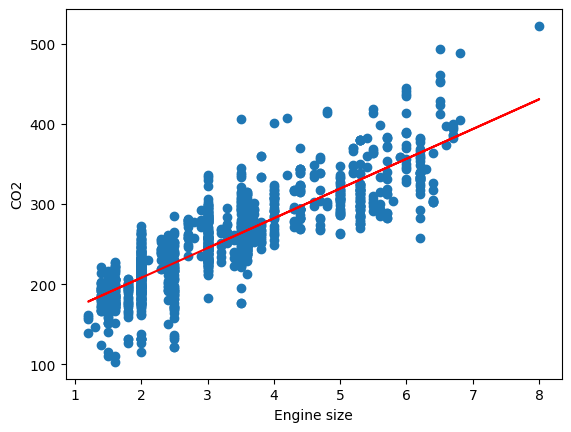

In [23]:
plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred, color='red')
plt.xlabel('Engine size')
plt.ylabel('CO2')
plt.show()

### Multiple linear regression

In [24]:
# using numeric columns + fuel type (converted using get_dummies)
data = pd.get_dummies(df[['engine_size','cylinders','fc_comb','fuel_type','co2']], columns=['fuel_type'], drop_first=True)
X = data.drop('co2', axis=1)
y = data['co2']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred = mlr.predict(X_test)

In [25]:
print('R2 :', r2_score(y_test, y_pred))
print('MAE:', mean_absolute_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))

R2 : 0.9873281724400916
MAE: 3.5138242557706643
RMSE: 6.762329446893271


In [26]:
pd.DataFrame({'feature': X.columns, 'coefficient': mlr.coef_})

,feature,coefficient
0,engine_size,3.562110e-01
1,cylinders,6.836424e-01
2,fc_comb,2.218686e+01
3,fuel_type_E,-1.440662e+02
4,fuel_type_N,1.278977e-13
5,fuel_type_X,-3.070766e+01
6,fuel_type_Z,-3.046421e+01


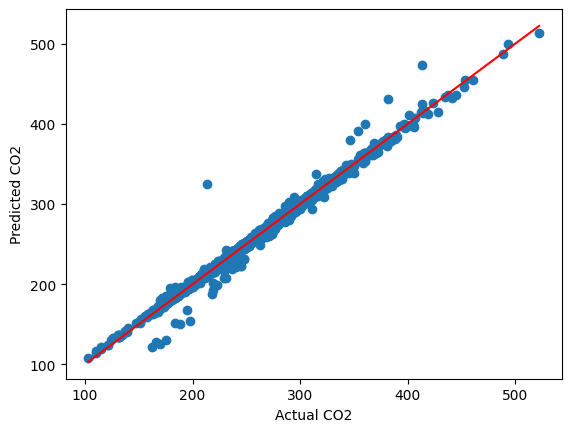

In [27]:
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Actual CO2')
plt.ylabel('Predicted CO2')
plt.show()

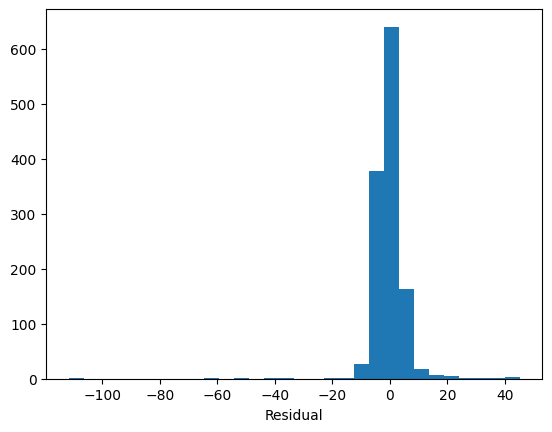

In [28]:
# residuals
residuals = y_test - y_pred
plt.hist(residuals, bins=30)
plt.xlabel('Residual')
plt.show()

## 3. Logistic Regression

Logistic regression is for classification, so I made a new target column: 1 (high emitter) if CO2 is above the median, otherwise 0 (low emitter).

In [29]:
median = df['co2'].median()
df['high_co2'] = (df['co2'] > median).astype(int)
print(median)
df['high_co2'].value_counts()

246.0


high_co2
0    3200
1    3082
Name: count, dtype: int64

In [30]:
data = pd.get_dummies(df[['engine_size','cylinders','fc_comb','fuel_type','high_co2']], columns=['fuel_type'], drop_first=True)
X = data.drop('high_co2', axis=1)
y = data['high_co2']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [31]:
# scaling so the model converges properly
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

log = LogisticRegression(max_iter=1000)
log.fit(X_train_s, y_train)
y_pred = log.predict(X_test_s)

In [32]:
print('Accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9840891010342084
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       640
           1       0.98      0.98      0.98       617

    accuracy                           0.98      1257
   macro avg       0.98      0.98      0.98      1257
weighted avg       0.98      0.98      0.98      1257



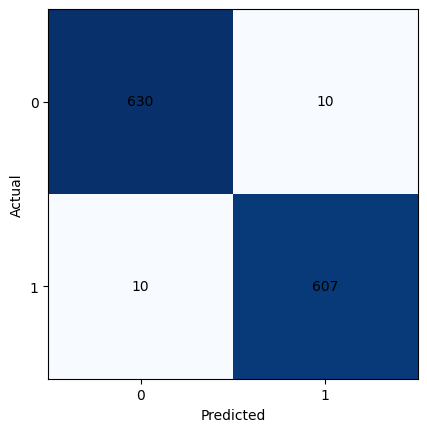

In [33]:
cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.xticks([0,1])
plt.yticks([0,1])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()